In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix,classification_report
import joblib

In [4]:
df = pd.read_csv("/content/customer_purchase_data.csv")

In [5]:
df.head()

,Age,Gender,AnnualIncome,NumberOfPurchases,ProductCategory,TimeSpentOnWebsite,LoyaltyProgram,DiscountsAvailed,PurchaseStatus
0,40,1,66120.267939,8,0,30.568601,0,5,1
1,20,1,23579.773583,4,2,38.240097,0,5,0
2,27,1,127821.306432,11,2,31.633212,1,0,1
3,24,1,137798.623120,19,3,46.167059,0,4,1
4,31,1,99300.964220,19,1,19.823592,0,0,1


In [6]:
df.shape

(1500, 9)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 1500 non-null   int64  
 1   Gender              1500 non-null   int64  
 2   AnnualIncome        1500 non-null   float64
 3   NumberOfPurchases   1500 non-null   int64  
 4   ProductCategory     1500 non-null   int64  
 5   TimeSpentOnWebsite  1500 non-null   float64
 6   LoyaltyProgram      1500 non-null   int64  
 7   DiscountsAvailed    1500 non-null   int64  
 8   PurchaseStatus      1500 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 105.6 KB


In [8]:
df.describe()

,Age,Gender,AnnualIncome,NumberOfPurchases,ProductCategory,TimeSpentOnWebsite,LoyaltyProgram,DiscountsAvailed,PurchaseStatus
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.00000
mean,44.298667,0.504667,84249.164338,10.420000,2.012667,30.469040,0.326667,2.555333,0.43200
std,15.537259,0.500145,37629.493078,5.887391,1.428005,16.984392,0.469151,1.705152,0.49552
min,18.000000,0.000000,20001.512518,0.000000,0.000000,1.037023,0.000000,0.000000,0.00000
25%,31.000000,0.000000,53028.979155,5.000000,1.000000,16.156700,0.000000,1.000000,0.00000
50%,45.000000,1.000000,83699.581476,11.000000,2.000000,30.939516,0.000000,3.000000,0.00000
75%,57.000000,1.000000,117167.772858,15.000000,3.000000,44.369863,1.000000,4.000000,1.00000
max,70.000000,1.000000,149785.176481,20.000000,4.000000,59.991105,1.000000,5.000000,1.00000


In [9]:
df['PurchaseStatus'].value_counts()

,count
PurchaseStatus,
0,852
1,648


In [10]:
df["PurchaseStatus"].value_counts(normalize=True)

,proportion
PurchaseStatus,
0,0.568
1,0.432


In [11]:
df.isnull().sum()

,0
Age,0
Gender,0
AnnualIncome,0
NumberOfPurchases,0
ProductCategory,0
TimeSpentOnWebsite,0
LoyaltyProgram,0
DiscountsAvailed,0
PurchaseStatus,0


In [12]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
1495,False
1496,False
1497,False
1498,False


In [13]:
df.duplicated().sum()

np.int64(112)

In [14]:
df.drop_duplicates(inplace=True)

In [15]:
df.shape

(1388, 9)

In [16]:
df.corr()["PurchaseStatus"].sort_values(ascending=False)

,PurchaseStatus
PurchaseStatus,1.000000
LoyaltyProgram,0.318059
DiscountsAvailed,0.296606
TimeSpentOnWebsite,0.282127
NumberOfPurchases,0.219116
AnnualIncome,0.191218
ProductCategory,0.014349
Gender,0.008856
Age,-0.253598


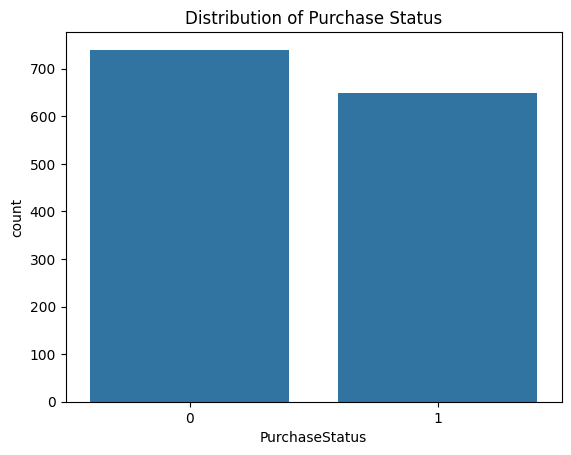

In [17]:
sns.countplot(x="PurchaseStatus", data=df)
plt.title("Distribution of Purchase Status")
plt.show()

In [18]:
q1 = df['Age'].quantile(0.25)
q3 = df['Age'].quantile(0.75)
iqr = q3 - q1
print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)

lowerb = q1 -1.5*iqr
upperb = q3 +1.5*iqr
print("Lower Bound:", lowerb)
print("Upper Bound:", upperb)

outliers = df[(df['Age'] <lowerb) | (df['Age']> upperb)]
print("Outliers:", outliers)

Q1: 30.75
Q3: 57.0
IQR: 26.25
Lower Bound: -8.625
Upper Bound: 96.375
Outliers: Empty DataFrame
Columns: [Age, Gender, AnnualIncome, NumberOfPurchases, ProductCategory, TimeSpentOnWebsite, LoyaltyProgram, DiscountsAvailed, PurchaseStatus]
Index: []


{'whiskers': [<matplotlib.lines.Line2D at 0x7dd6d3bd6c10>,
 'caps': [<matplotlib.lines.Line2D at 0x7dd6d3bd6e90>,
 'boxes': [<matplotlib.lines.Line2D at 0x7dd6d3bd6ad0>],
 'medians': [<matplotlib.lines.Line2D at 0x7dd6d3bd7110>],
 'fliers': [<matplotlib.lines.Line2D at 0x7dd6d3bd7250>],
 'means': []}

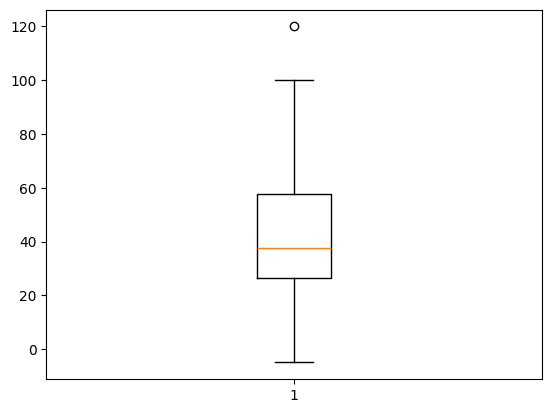

In [19]:
s = [-5,2,25,30,35,40,50,60,100,120]
plt.boxplot(x=s,data=s)

In [20]:
s_series = pd.Series(s)
Q1  = s_series.quantile(0.25)
Q3 = s_series.quantile(0.75)
iqr = Q3 - Q1
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", iqr)

lowerb = Q1 -1.5*iqr
upperb = Q3 +1.5*iqr
print("Lower Bound:", lowerb)
print("Upper Bound:", upperb)
outliers = s_series[(s_series < lowerb) | (s_series > upperb)]
print("Outliers:", outliers)

Q1: 26.25
Q3: 57.5
IQR: 31.25
Lower Bound: -20.625
Upper Bound: 104.375
Outliers: 9    120
dtype: int64


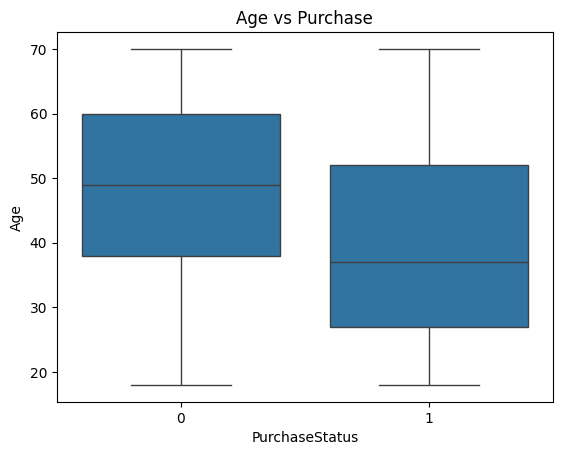

In [21]:
sns.boxplot(x="PurchaseStatus", y="Age", data=df)
plt.title("Age vs Purchase")
plt.show()

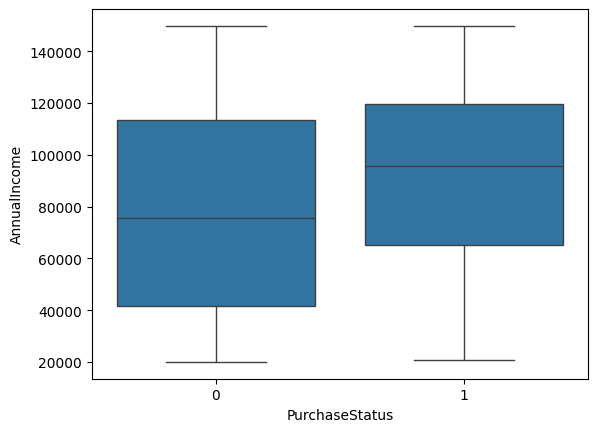

In [22]:
sns.boxplot(x="PurchaseStatus", y="AnnualIncome", data=df)
plt.show()

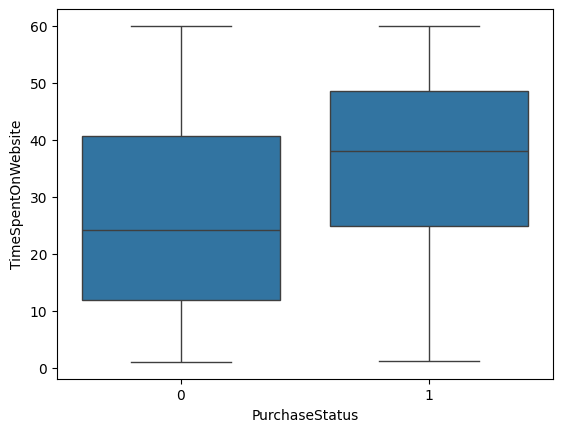

In [23]:
sns.boxplot(x="PurchaseStatus", y="TimeSpentOnWebsite", data=df)
plt.show()

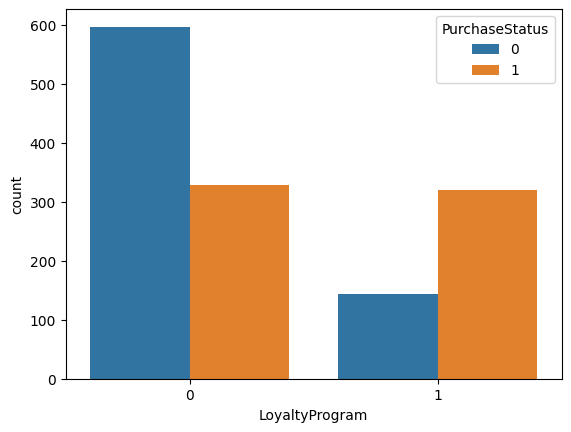

In [24]:
sns.countplot(x="LoyaltyProgram", hue="PurchaseStatus", data=df)
plt.show()

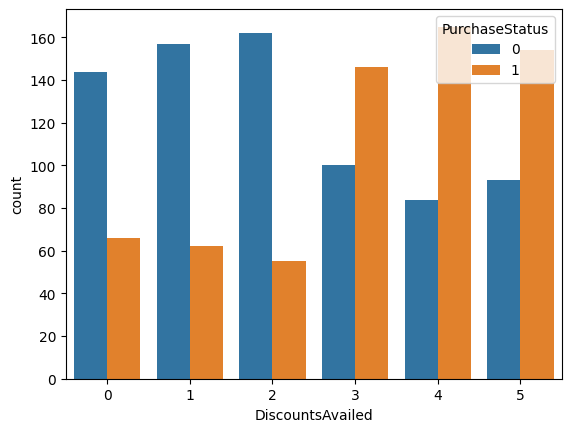

In [25]:
sns.countplot(x="DiscountsAvailed", hue="PurchaseStatus", data=df)
plt.show()

In [26]:
X = df.drop('PurchaseStatus', axis=1)
Y = df['PurchaseStatus']

In [27]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [28]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [29]:
lr = LogisticRegression()
lr.fit(X_train_scaled, Y_train)

LogisticRegression()

In [30]:
lr_pred = lr.predict(X_test_scaled)
print(f"Logistic Regression Accuracy: ",accuracy_score(Y_test, lr_pred))
print(f"Roc-AUC: ",roc_auc_score(Y_test, lr_pred))

Logistic Regression Accuracy:  0.8525179856115108
Roc-AUC:  0.8514905572030592


In [31]:
dt = DecisionTreeClassifier()
dt.fit(X_train, Y_train)

DecisionTreeClassifier()

In [33]:
dt_pred = dt.predict(X_test)
print(f"Decision Tree Accuracy: ",accuracy_score(Y_test, dt_pred))
print(f"ROC-AUC: ",roc_auc_score(Y_test, dt_pred))

Decision Tree Accuracy:  0.8561151079136691
ROC-AUC:  0.8558867904895686


In [34]:
rf = RandomForestClassifier()
rf.fit(X_train, Y_train)

RandomForestClassifier()

In [35]:
rf_pred = rf.predict(X_test)
print(f"Random Forest Classifier Accuracy: ",accuracy_score(Y_test, rf_pred))
print(f"Roc-AUC: ",roc_auc_score(Y_test, rf_pred))

Random Forest Classifier Accuracy:  0.9280575539568345
Roc-AUC:  0.9266427345091305


In [36]:
xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    eval_metric="logloss"
)

xgb.fit(X_train_scaled, Y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [37]:
xgb_pred = xgb.predict(X_test_scaled)
print(f"xgb Accuracy: ",accuracy_score(Y_test, xgb_pred))
print(f"Roc-AUC: ",roc_auc_score(Y_test, xgb_pred))

xgb Accuracy:  0.8992805755395683
Roc-AUC:  0.8982363040424536


In [38]:
results = pd.DataFrame({
    "Model": ["Logistic Regression","Decision Tree", "Random Forest", "XGBoost"],
    "Accuracy": [
        accuracy_score(Y_test, lr_pred),
        accuracy_score(Y_test, dt_pred),
        accuracy_score(Y_test, rf_pred),
        accuracy_score(Y_test, xgb_pred)
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.852518
1,Decision Tree,0.856115
2,Random Forest,0.928058
3,XGBoost,0.899281


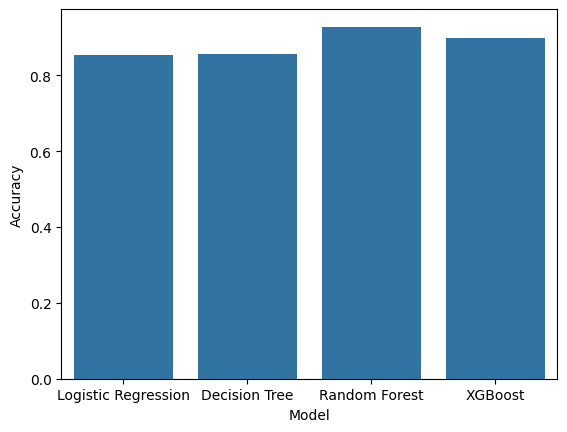

In [39]:
sns.barplot(x="Model", y="Accuracy", data=results)
plt.show()

In [40]:
confusion_matrix(Y_test, lr_pred)

array([[129,  20],
       [ 21, 108]])

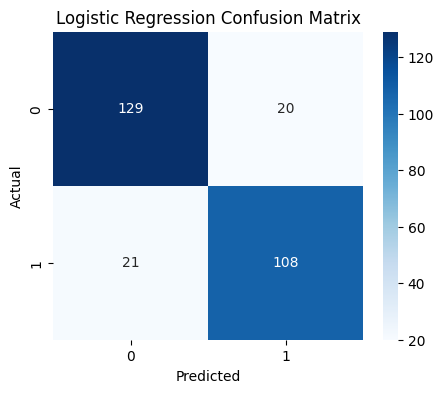

In [41]:
cm_lr = confusion_matrix(Y_test, lr_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [42]:
confusion_matrix(Y_test, dt_pred)

array([[128,  21],
       [ 19, 110]])

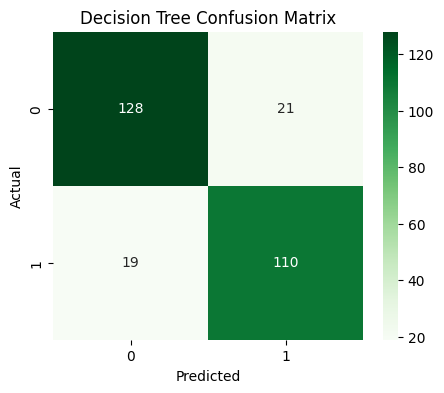

In [43]:
cm_dt = confusion_matrix(Y_test, dt_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Greens")
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [44]:
confusion_matrix(Y_test, rf_pred)

array([[141,   8],
       [ 12, 117]])

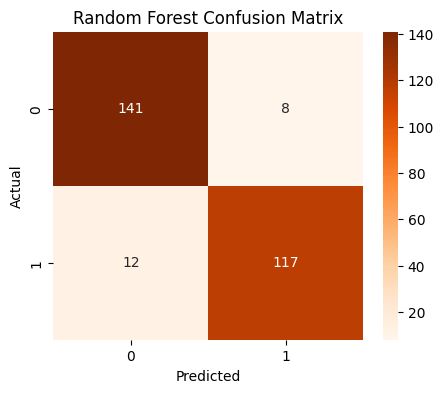

In [45]:
cm_rf = confusion_matrix(Y_test, rf_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Oranges")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [46]:
confusion_matrix(Y_test, xgb_pred)

array([[136,  13],
       [ 15, 114]])

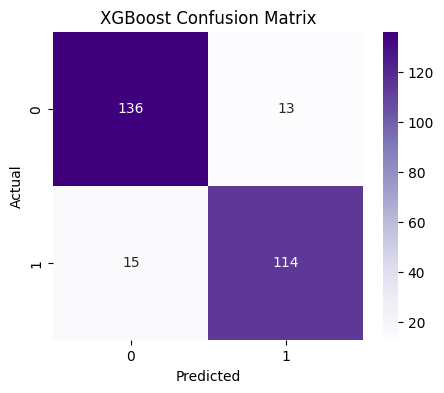

In [47]:
cm_xgb = confusion_matrix(Y_test, xgb_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm_xgb, annot=True, fmt="d", cmap="Purples")
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [48]:
importance = rf.feature_importances_

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

importance_df

,Feature,Importance
5,TimeSpentOnWebsite,0.209796
0,Age,0.176344
2,AnnualIncome,0.162741
7,DiscountsAvailed,0.154155
3,NumberOfPurchases,0.143190
6,LoyaltyProgram,0.099462
4,ProductCategory,0.038793
1,Gender,0.015520


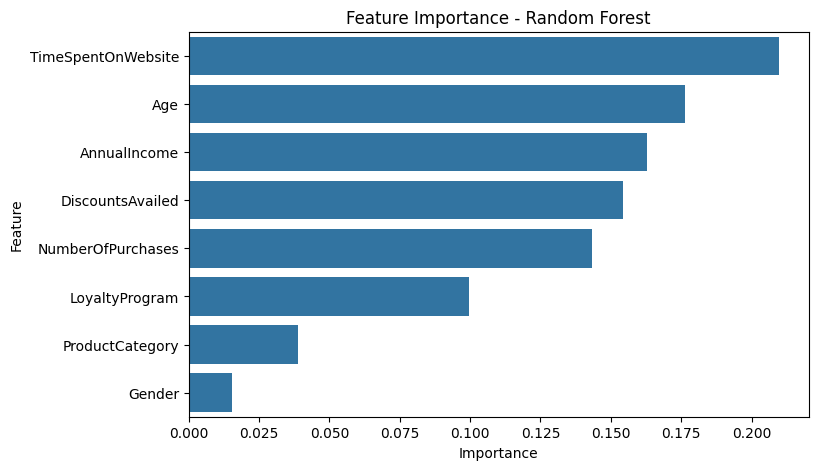

In [49]:
plt.figure(figsize=(8,5))
sns.barplot(x="Importance", y="Feature", data=importance_df)
plt.title("Feature Importance - Random Forest")
plt.show()

In [50]:
print("Logistic Regression Report")
print(classification_report(Y_test, lr_pred))

Logistic Regression Report
              precision    recall  f1-score   support

           0       0.86      0.87      0.86       149
           1       0.84      0.84      0.84       129

    accuracy                           0.85       278
   macro avg       0.85      0.85      0.85       278
weighted avg       0.85      0.85      0.85       278



In [51]:
print("Decision Tree Report")
print(classification_report(Y_test, dt_pred))

Decision Tree Report
              precision    recall  f1-score   support

           0       0.87      0.86      0.86       149
           1       0.84      0.85      0.85       129

    accuracy                           0.86       278
   macro avg       0.86      0.86      0.86       278
weighted avg       0.86      0.86      0.86       278



In [52]:
print("Decision Tree Report")
print(classification_report(Y_test, dt_pred))

Decision Tree Report
              precision    recall  f1-score   support

           0       0.87      0.86      0.86       149
           1       0.84      0.85      0.85       129

    accuracy                           0.86       278
   macro avg       0.86      0.86      0.86       278
weighted avg       0.86      0.86      0.86       278



In [53]:
print("Random Forest Report")
print(classification_report(Y_test, rf_pred))

Random Forest Report
              precision    recall  f1-score   support

           0       0.92      0.95      0.93       149
           1       0.94      0.91      0.92       129

    accuracy                           0.93       278
   macro avg       0.93      0.93      0.93       278
weighted avg       0.93      0.93      0.93       278



In [54]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(rf, X, Y, cv=5)

print("Cross Validation Scores:", cv_scores)
print("Average CV Score:", cv_scores.mean())

Cross Validation Scores: [0.92446043 0.92805755 0.94604317 0.90974729 0.92779783]
Average CV Score: 0.9272212554865854


In [55]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred
}

results = []

for name, preds in models.items():
    results.append([
        name,
        accuracy_score(Y_test, preds),
        precision_score(Y_test, preds),
        recall_score(Y_test, preds),
        f1_score(Y_test, preds)
    ])

metrics_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
metrics_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.852518,0.843750,0.837209,0.840467
1,Decision Tree,0.856115,0.839695,0.852713,0.846154
2,Random Forest,0.928058,0.936000,0.906977,0.921260
3,XGBoost,0.899281,0.897638,0.883721,0.890625


In [56]:

# Save Logistic Regression model
joblib.dump(lr, 'logistic_regression_model.pkl')
print("Logistic Regression model saved as logistic_regression_model.pkl")

# Save Decision Tree model
joblib.dump(dt, 'decision_tree_model.pkl')
print("Decision Tree model saved as decision_tree_model.pkl")

# Save Random Forest model
joblib.dump(rf, 'random_forest_model.pkl')
print("Random Forest model saved as random_forest_model.pkl")

# Save using XGBoost native format
xgb.get_booster().save_model("xgboost_model.json")
print("XGBoost model saved as xgboost_model.json")

Logistic Regression model saved as logistic_regression_model.pkl
Decision Tree model saved as decision_tree_model.pkl
Random Forest model saved as random_forest_model.pkl
XGBoost model saved as xgboost_model.json


In [57]:
joblib.dump(scaler, 'preprocessor.pkl')
print("StandardScaler object saved as preprocessor.pkl")

StandardScaler object saved as preprocessor.pkl
